In [1]:
# Adapted from PyTorch's "What is torch.nn really?" by Jeremy Howard / fast.ai.
# Thanks to Rachel Thomas and Francisco Ingham. See README.md and LICENSE.
# Run all cells in order; the interpretability experiments reuse trained weights.
%matplotlib inline
import random
import copy
import torch
import numpy as np
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)


In [2]:
from pathlib import Path
import hashlib
import requests

DATA_PATH = Path("data")
PATH = DATA_PATH / "mnist"
PATH.mkdir(parents=True, exist_ok=True)
URL = "https://raw.githubusercontent.com/pytorch/tutorials/main/_static/"
FILENAME = "mnist.pkl.gz"
expected_sha256 = "0c66b22fbfd977a01005ad5c02363406bc02a29cc2bc8e3c99e0f2aa2550a9ed"
if not (PATH / FILENAME).exists():
    response = requests.get(URL + FILENAME, timeout=120)
    response.raise_for_status()
    assert hashlib.sha256(response.content).hexdigest() == expected_sha256
    (PATH / FILENAME).write_bytes(response.content)
assert hashlib.sha256((PATH / FILENAME).read_bytes()).hexdigest() == expected_sha256


In [3]:
import pickle
import gzip

with gzip.open((PATH / FILENAME).as_posix(), "rb") as f:
        ((x_train, y_train), (x_valid, y_valid), _) = pickle.load(f, encoding="latin-1")


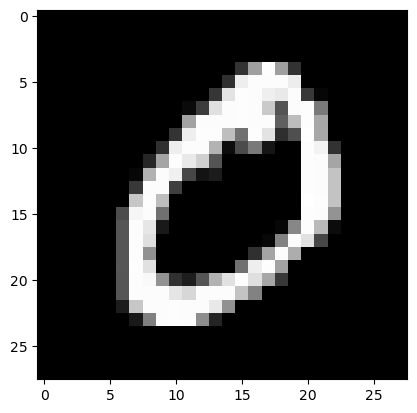

(50000, 784)


In [4]:
from matplotlib import pyplot
import numpy as np

pyplot.imshow(x_train[1].reshape((28, 28)), cmap="gray")
# ``pyplot.show()`` only if not on Colab
pyplot.show()
try:
    import google.colab
except ImportError:
    pyplot.show()
print(x_train.shape)


In [5]:
import torch

x_train, y_train, x_valid, y_valid = map(
    torch.tensor, (x_train, y_train, x_valid, y_valid)
)
n, c = x_train.shape
print(x_train, y_train)
print(x_train.shape)
print(y_train.min(), y_train.max())


tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]]) tensor([5, 0, 4,  ..., 8, 4, 8])
torch.Size([50000, 784])
tensor(0) tensor(9)


In [6]:
print(x_valid.shape)


torch.Size([10000, 784])


In [7]:
import math

weights = torch.randn(784, 10) / math.sqrt(784)
weights.requires_grad_()
bias = torch.zeros(10, requires_grad=True)


In [8]:
# Define the scratch example before inspecting it.
tensor_2 = torch.rand(1, 10)

def log_softmax(x):
    return x - torch.logsumexp(x, dim=-1, keepdim=True)


In [9]:
tensor_2


tensor([[0.3696, 0.8956, 0.4543, 0.8566, 0.5243, 0.5519, 0.0777, 0.3272, 0.5251,
         0.7285]])

In [10]:
tensor_2.exp()


tensor([[1.4472, 2.4488, 1.5751, 2.3551, 1.6892, 1.7366, 1.0808, 1.3871, 1.6906,
         2.0719]])

In [11]:
tensor_2.exp().shape


torch.Size([1, 10])

In [12]:
tensor_2.exp()


tensor([[1.4472, 2.4488, 1.5751, 2.3551, 1.6892, 1.7366, 1.0808, 1.3871, 1.6906,
         2.0719]])

In [13]:
tensor_2.exp().unsqueeze(dim=1).shape


torch.Size([1, 1, 10])

In [14]:
tensor_2.exp().unsqueeze(dim=1)


tensor([[[1.4472, 2.4488, 1.5751, 2.3551, 1.6892, 1.7366, 1.0808, 1.3871,
          1.6906, 2.0719]]])

In [15]:
tensor_2


tensor([[0.3696, 0.8956, 0.4543, 0.8566, 0.5243, 0.5519, 0.0777, 0.3272, 0.5251,
         0.7285]])

In [16]:
tensor_2.exp()


tensor([[1.4472, 2.4488, 1.5751, 2.3551, 1.6892, 1.7366, 1.0808, 1.3871, 1.6906,
         2.0719]])

In [17]:
tensor_2.exp().sum(-1).log().unsqueeze(-1)


tensor([[2.8612]])

In [18]:
tensor_2.shape


torch.Size([1, 10])

In [19]:
tensor_2 = torch.rand(size=(1,10))
log_softmax(tensor_2 )


tensor([[-2.3547, -2.5603, -2.4484, -2.0219, -2.1182, -2.2811, -2.8121, -2.6199,
         -2.1325, -2.0016]])

In [20]:
tensor_2 = torch.rand(size=(1,2))
print(tensor_2)
print(tensor_2.exp())
print(tensor_2.exp().sum(-1))
print(tensor_2.exp().sum(-1).log())
print(tensor_2.exp().sum(-1).log().unsqueeze(-1))
print((tensor_2 - tensor_2.exp().sum(-1).log().unsqueeze(-1)))


tensor([[0.2636, 0.7125]])
tensor([[1.3016, 2.0390]])
tensor([3.3406])
tensor([1.2062])
tensor([[1.2062]])
tensor([[-0.9425, -0.4937]])


In [21]:
def log_softmax(x):
    return x - torch.logsumexp(x, dim=-1, keepdim=True)

def model(xb):
    return log_softmax(xb @ weights + bias)


In [22]:
x_train[:64].shape


torch.Size([64, 784])

In [23]:
bs = 64
xb, yb = x_train[:bs], y_train[:bs]
preds = model(xb)
print(preds[0], preds.shape)


tensor([-2.5452, -2.0790, -2.1832, -2.6221, -2.3670, -2.3854, -2.9432, -2.4391,
        -1.8657, -2.0355], grad_fn=<SelectBackward0>) torch.Size([64, 10])


In [24]:
def viz(input,target):
    return -input[range(target.shape[0]), target]

def nll(input, target):
    return -input[range(target.shape[0]), target].mean() # select the log likelihood associated with th right class 
    # we want to ultimately minimize this number. to minimize this number we want to select the log likelihoods that are the biggest since 
    # those create the largest probabilities. Thus, picking those creates the smallest positive numbers and we end up minimzing this mean 
    # which is a positive number

loss_func = nll


In [25]:
yb.shape


torch.Size([64])

In [26]:
preds.shape


torch.Size([64, 10])

In [27]:
preds[0]


tensor([-2.5452, -2.0790, -2.1832, -2.6221, -2.3670, -2.3854, -2.9432, -2.4391,
        -1.8657, -2.0355], grad_fn=<SelectBackward0>)

In [28]:
preds[0].exp()


tensor([0.0785, 0.1251, 0.1127, 0.0726, 0.0938, 0.0921, 0.0527, 0.0872, 0.1548,
        0.1306], grad_fn=<ExpBackward0>)

In [29]:
y_train[0]


tensor(5)

In [30]:
viz(preds,yb)


tensor([2.3854, 2.8319, 2.6471, 1.7632, 2.0555, 2.2289, 2.4128, 2.7565, 2.3626,
        2.8045, 2.6815, 2.6601, 2.6831, 2.1576, 2.2713, 2.5188, 2.3886, 1.8937,
        2.2510, 2.1568, 2.8895, 2.8814, 2.2153, 1.8280, 2.4693, 1.8695, 2.6246,
        2.8681, 2.6466, 2.4187, 2.7360, 1.4558, 2.3638, 1.9714, 2.9935, 2.5023,
        2.1867, 3.1755, 2.2909, 2.3232, 2.2570, 1.9071, 2.4344, 2.1044, 2.8336,
        1.7655, 1.9608, 2.6692, 2.0519, 2.6694, 2.5259, 2.9554, 2.2097, 2.5492,
        1.9924, 1.7902, 2.5686, 2.2006, 2.5986, 1.9338, 2.4872, 2.9115, 2.2985,
        3.4294], grad_fn=<NegBackward0>)

In [31]:
yb = y_train[0:bs]
print(loss_func(preds, yb))


tensor(2.4020, grad_fn=<NegBackward0>)


In [32]:
def accuracy(out, yb):
    preds = torch.argmax(out, dim=1)
    return (preds == yb).float().mean()


In [33]:
print(accuracy(preds, yb))


tensor(0.0938)


In [34]:
from IPython.core.debugger import set_trace

lr = 0.5  # learning rate
epochs = 2  # how many epochs to train for

for epoch in range(epochs):
    for i in range((n - 1) // bs + 1):
        #         set_trace()
        start_i = i * bs
        end_i = start_i + bs
        xb = x_train[start_i:end_i]
        yb = y_train[start_i:end_i]
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        with torch.no_grad():
            weights -= weights.grad * lr
            bias -= bias.grad * lr
            weights.grad.zero_()
            bias.grad.zero_()


In [35]:
print(loss_func(model(xb), yb), accuracy(model(xb), yb))


tensor(0.0813, grad_fn=<NegBackward0>) tensor(1.)


In [36]:
import torch.nn.functional as F

loss_func = F.cross_entropy

def model(xb):
    return xb @ weights + bias


In [37]:
print(loss_func(model(xb), yb), accuracy(model(xb), yb))


tensor(0.0813, grad_fn=<NllLossBackward0>) tensor(1.)


In [38]:
from torch import nn

class Mnist_Logistic(nn.Module):
    def __init__(self):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(784, 10) / math.sqrt(784))
        self.bias = nn.Parameter(torch.zeros(10))

    def forward(self, xb):
        return xb @ self.weights + self.bias


In [39]:
model = Mnist_Logistic()


In [40]:
print(loss_func(model(xb), yb))


tensor(2.4349, grad_fn=<NllLossBackward0>)


In [41]:
def fit():
    for epoch in range(epochs):
        for i in range((n - 1) // bs + 1):
            start_i = i * bs
            end_i = start_i + bs
            xb = x_train[start_i:end_i]
            yb = y_train[start_i:end_i]
            pred = model(xb)
            loss = loss_func(pred, yb)

            loss.backward()
            with torch.no_grad():
                for p in model.parameters():
                    p -= p.grad * lr
                model.zero_grad()

fit()


In [42]:
print(loss_func(model(xb), yb))


tensor(0.0803, grad_fn=<NllLossBackward0>)


In [43]:
class Mnist_Logistic(nn.Module):
    def __init__(self):
        super().__init__()
        self.lin = nn.Linear(784, 10)

    def forward(self, xb):
        return self.lin(xb)


In [44]:
model = Mnist_Logistic()
print(loss_func(model(xb), yb))


tensor(2.3949, grad_fn=<NllLossBackward0>)


In [45]:
fit()

print(loss_func(model(xb), yb))


tensor(0.0820, grad_fn=<NllLossBackward0>)


In [46]:
from torch import optim


In [47]:
def get_model():
    model = Mnist_Logistic()
    return model, optim.SGD(model.parameters(), lr=lr)

model, opt = get_model()
print(loss_func(model(xb), yb))

for epoch in range(epochs):
    for i in range((n - 1) // bs + 1):
        start_i = i * bs
        end_i = start_i + bs
        xb = x_train[start_i:end_i]
        yb = y_train[start_i:end_i]
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))


tensor(2.3273, grad_fn=<NllLossBackward0>)


tensor(0.0827, grad_fn=<NllLossBackward0>)


In [48]:
from torch.utils.data import TensorDataset


In [49]:
train_ds = TensorDataset(x_train, y_train)


In [50]:
model, opt = get_model()

for epoch in range(epochs):
    for i in range((n - 1) // bs + 1):
        xb, yb = train_ds[i * bs: i * bs + bs]
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))


tensor(0.0802, grad_fn=<NllLossBackward0>)


In [51]:
from torch.utils.data import DataLoader

train_ds = TensorDataset(x_train, y_train)
train_dl = DataLoader(train_ds, batch_size=bs)


In [52]:
model, opt = get_model()

for epoch in range(epochs):
    for xb, yb in train_dl:
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

print(loss_func(model(xb), yb))


tensor(0.0801, grad_fn=<NllLossBackward0>)


In [53]:
train_ds = TensorDataset(x_train, y_train)
train_dl = DataLoader(train_ds, batch_size=bs, shuffle=True)

valid_ds = TensorDataset(x_valid, y_valid)
valid_dl = DataLoader(valid_ds, batch_size=bs * 2)


In [54]:
model, opt = get_model()

for epoch in range(epochs):
    model.train()
    for xb, yb in train_dl:
        pred = model(xb)
        loss = loss_func(pred, yb)

        loss.backward()
        opt.step()
        opt.zero_grad()

    model.eval()
    with torch.no_grad():
        valid_loss = sum(loss_func(model(xb), yb) for xb, yb in valid_dl)

    print(epoch, valid_loss / len(valid_dl))


0 tensor(0.3067)


1 tensor(0.2793)


In [55]:
def loss_batch(model, loss_func, xb, yb, opt=None):
    loss = loss_func(model(xb), yb)

    if opt is not None:
        loss.backward()
        opt.step()
        opt.zero_grad()

    return loss.item(), len(xb)


In [56]:
import numpy as np

def fit(epochs, model, loss_func, opt, train_dl, valid_dl):
    for epoch in range(epochs):
        model.train()
        for xb, yb in train_dl:
            loss_batch(model, loss_func, xb, yb, opt)

        model.eval()
        with torch.no_grad():
            losses, nums = zip(
                *[loss_batch(model, loss_func, xb, yb) for xb, yb in valid_dl]
            )
        val_loss = np.sum(np.multiply(losses, nums)) / np.sum(nums)

        print(epoch, val_loss)


In [57]:
def get_data(train_ds, valid_ds, bs):
    return (
        DataLoader(train_ds, batch_size=bs, shuffle=True),
        DataLoader(valid_ds, batch_size=bs * 2),
    )


In [58]:
train_dl, valid_dl = get_data(train_ds, valid_ds, bs)
model, opt = get_model()
fit(epochs, model, loss_func, opt, train_dl, valid_dl)


0 0.33404030644893645


1 0.28626376625299454


In [59]:
# Retain the trained linear classifier before the tutorial reassigns model.
trained_linear = copy.deepcopy(model).cpu().eval()


In [60]:
class Mnist_CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1)
        self.conv2 = nn.Conv2d(16, 16, kernel_size=3, stride=2, padding=1)
        self.conv3 = nn.Conv2d(16, 10, kernel_size=3, stride=2, padding=1)

    def forward(self, xb):
        xb = xb.view(-1, 1, 28, 28)
        xb = F.relu(self.conv1(xb))
        xb = F.relu(self.conv2(xb))
        xb = F.relu(self.conv3(xb))
        xb = F.avg_pool2d(xb, 4)
        return xb.view(-1, xb.size(1))

lr = 0.1


In [61]:
model = Mnist_CNN()
opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

fit(epochs, model, loss_func, opt, train_dl, valid_dl)


0 0.3426044387817383


1 0.30055388227701185


In [62]:
class Lambda(nn.Module):
    def __init__(self, func):
        super().__init__()
        self.func = func

    def forward(self, x):
        return self.func(x)


def preprocess(x):
    return x.view(-1, 1, 28, 28)


In [63]:
model = nn.Sequential(
    Lambda(preprocess),
    nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 16, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 10, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.AvgPool2d(4),
    Lambda(lambda x: x.view(x.size(0), -1)),
)

opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

fit(epochs, model, loss_func, opt, train_dl, valid_dl)


0 0.3177019569158554


1 0.24315667788982392


In [64]:
def preprocess(x, y):
    return x.view(-1, 1, 28, 28), y


class WrappedDataLoader:
    def __init__(self, dl, func):
        self.dl = dl
        self.func = func

    def __len__(self):
        return len(self.dl)

    def __iter__(self):
        for b in self.dl:
            yield (self.func(*b))

train_dl, valid_dl = get_data(train_ds, valid_ds, bs)
train_dl = WrappedDataLoader(train_dl, preprocess)
valid_dl = WrappedDataLoader(valid_dl, preprocess)


In [65]:
model = nn.Sequential(
    nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 16, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.Conv2d(16, 10, kernel_size=3, stride=2, padding=1),
    nn.ReLU(),
    nn.AdaptiveAvgPool2d(1),
    Lambda(lambda x: x.view(x.size(0), -1)),
)

opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)


In [66]:
fit(epochs, model, loss_func, opt, train_dl, valid_dl)


0 0.4075759238243103


1 0.2738394186496735


In [67]:
# If the current accelerator is available, we will use it. Otherwise, we use the CPU.
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")


Using cpu device


In [68]:
def preprocess(x, y):
    return x.view(-1, 1, 28, 28).to(device), y.to(device)


train_dl, valid_dl = get_data(train_ds, valid_ds, bs)
train_dl = WrappedDataLoader(train_dl, preprocess)
valid_dl = WrappedDataLoader(valid_dl, preprocess)


In [69]:
model.to(device)
opt = optim.SGD(model.parameters(), lr=lr, momentum=0.9)


In [70]:
fit(epochs, model, loss_func, opt, train_dl, valid_dl)


0 0.26133006496429445


1 0.21437087250947953


In [71]:
# Retain the final trained CNN: Conv -> ReLU -> Conv -> ReLU -> Conv -> ReLU -> pooling.
trained_cnn = copy.deepcopy(model).cpu().eval()
assert isinstance(trained_cnn[3], nn.ReLU)
intervention_layer = trained_cnn[3]  # Post-ReLU activations of the second convolution.
for net in (trained_linear, trained_cnn):
    net.requires_grad_(False)  # Input gradients still work; model weights stay fixed.
original_parameters = {k: v.clone() for k, v in trained_cnn.state_dict().items()}

# Channel selection uses training examples; evaluation uses separate validation examples.
# These are exploratory subsets, not a final test-set benchmark.
calibration_x = x_train[:512].reshape(-1, 1, 28, 28)
calibration_y = y_train[:512]
evaluation_x = x_valid[:512].reshape(-1, 1, 28, 28)
evaluation_y = y_valid[:512]

@torch.no_grad()
def logits_in_batches(net, images, batch_size=128):
    return torch.cat([net(chunk) for chunk in images.split(batch_size)])

def metrics(logits, labels):
    return {
        "loss": F.cross_entropy(logits, labels).item(),
        "accuracy": (logits.argmax(-1) == labels).float().mean().item(),
    }

linear_logits = logits_in_batches(trained_linear, evaluation_x.flatten(1))
cnn_logits = logits_in_batches(trained_cnn, evaluation_x)
summary = {
    "seed": SEED,
    "calibration_n": len(calibration_y),
    "evaluation_n": len(evaluation_y),
    "linear": metrics(linear_logits, evaluation_y),
    "cnn": metrics(cnn_logits, evaluation_y),
}
print(summary)


{'seed': 42, 'calibration_n': 512, 'evaluation_n': 512, 'linear': {'loss': 0.42181140184402466, 'accuracy': 0.888671875}, 'cnn': {'loss': 0.27102595567703247, 'accuracy': 0.921875}}


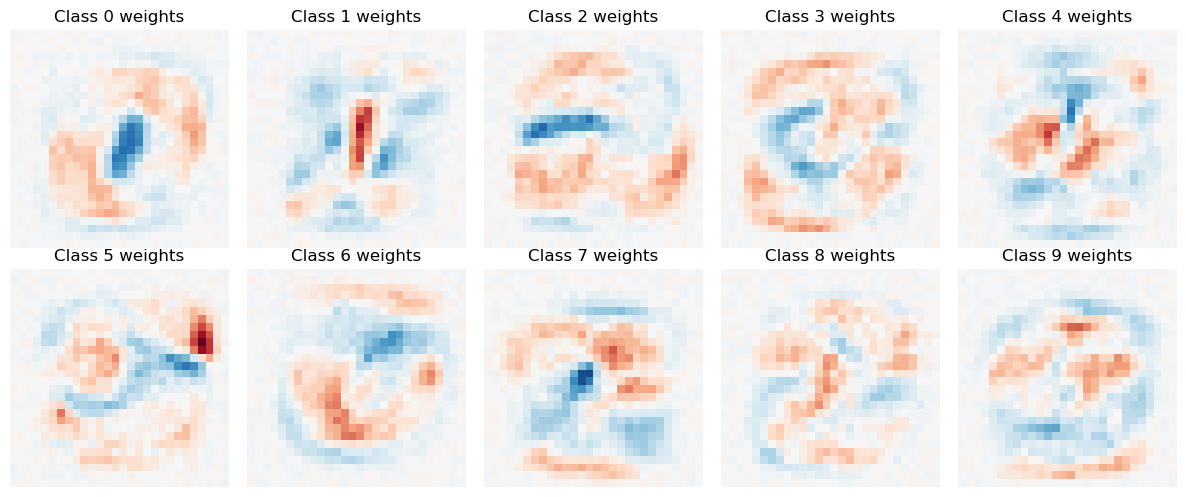

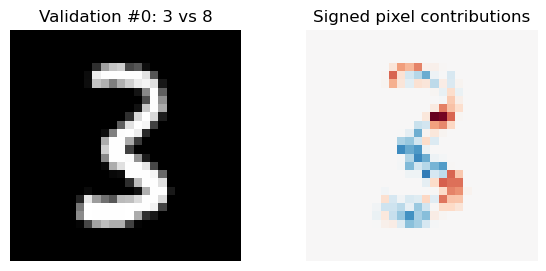

Margin 1.2158 = pixel sum -0.2097 + bias 1.4254


In [72]:
# 1. Inspect linear weights and decompose a class contrast exactly into pixel contributions.
weights_by_class = trained_linear.lin.weight.detach().reshape(10, 28, 28)
fig, axes = pyplot.subplots(2, 5, figsize=(12, 5))
bound = weights_by_class.abs().max().item()
for digit, ax in enumerate(axes.flat):
    ax.imshow(weights_by_class[digit], cmap="RdBu_r", vmin=-bound, vmax=bound)
    ax.set_title(f"Class {digit} weights")
    ax.axis("off")
pyplot.tight_layout()
pyplot.show()

correct = torch.where(linear_logits.argmax(-1) == evaluation_y)[0]
assert len(correct), "No correctly classified linear examples; inspect training."
linear_index = correct[0].item()
image = evaluation_x[linear_index].flatten()
target = evaluation_y[linear_index].item()
alternatives = linear_logits[linear_index].clone()
alternatives[target] = -torch.inf
foil = alternatives.argmax().item()
contrast_weights = trained_linear.lin.weight[target] - trained_linear.lin.weight[foil]
pixel_contributions = image * contrast_weights
bias_contribution = trained_linear.lin.bias[target] - trained_linear.lin.bias[foil]
actual_margin = linear_logits[linear_index, target] - linear_logits[linear_index, foil]
reconstructed_margin = pixel_contributions.sum() + bias_contribution
torch.testing.assert_close(reconstructed_margin, actual_margin, atol=1e-5, rtol=1e-5)
fig, axes = pyplot.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(image.reshape(28, 28), cmap="gray")
axes[0].set_title(f"Validation #{linear_index}: {target} vs {foil}")
scale = pixel_contributions.abs().max().item()
axes[1].imshow(pixel_contributions.reshape(28, 28), cmap="RdBu_r", vmin=-scale, vmax=scale)
axes[1].set_title("Signed pixel contributions")
for ax in axes:
    ax.axis("off")
pyplot.show()
print(f"Margin {actual_margin.item():.4f} = pixel sum {pixel_contributions.sum().item():.4f} + bias {bias_contribution.item():.4f}")
# Weight maps describe this linear decision rule, not universal digit templates.


Second-layer activation shape: (512, 16, 7, 7)


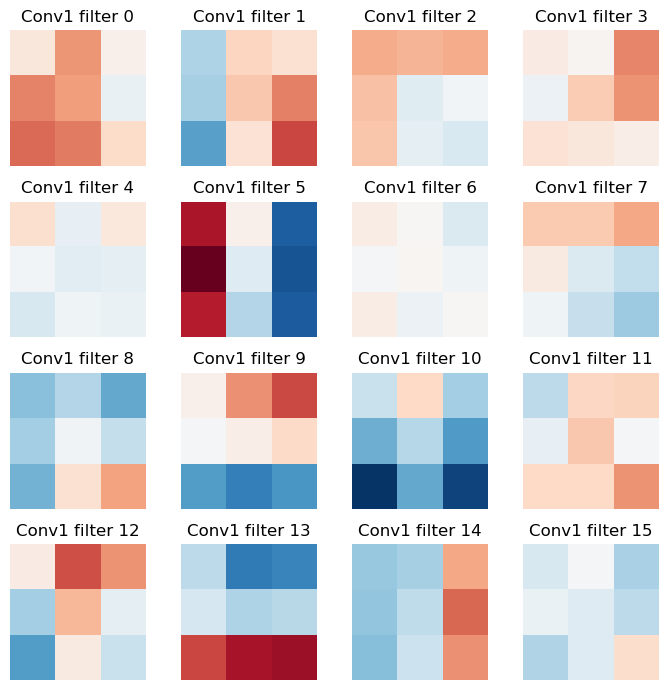

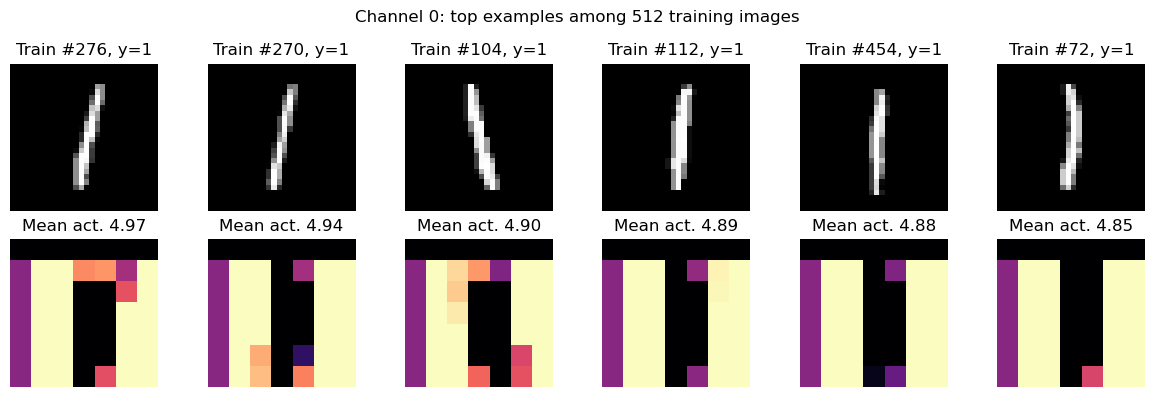

In [73]:
# 2. Capture internal activations and inspect filters and highly activating examples.
# Hooks are always removed, even if a forward pass raises an exception.
@torch.no_grad()
def capture_activations(images):
    captured = []
    handle = intervention_layer.register_forward_hook(
        lambda module, inputs, output: captured.append(output.detach().clone())
    )
    try:
        logits = logits_in_batches(trained_cnn, images)
    finally:
        handle.remove()
    return logits, torch.cat(captured)

calibration_logits, calibration_activations = capture_activations(calibration_x)
captured_logits, evaluation_activations = capture_activations(evaluation_x)
torch.testing.assert_close(captured_logits, cnn_logits)
channels = calibration_activations.shape[1]
print("Second-layer activation shape:", tuple(calibration_activations.shape))
fig, axes = pyplot.subplots(4, 4, figsize=(7, 7))
kernels = trained_cnn[0].weight.detach()[:, 0]
bound = kernels.abs().max().item()
for channel, ax in enumerate(axes.flat):
    ax.imshow(kernels[channel], cmap="RdBu_r", vmin=-bound, vmax=bound)
    ax.set_title(f"Conv1 filter {channel}")
    ax.axis("off")
pyplot.tight_layout()
pyplot.show()

active_channel = calibration_activations.mean((0, 2, 3)).argmax().item()
scores = calibration_activations[:, active_channel].mean((1, 2))
top_examples = scores.topk(6).indices
fig, axes = pyplot.subplots(2, 6, figsize=(12, 4))
for column, example in enumerate(top_examples.tolist()):
    axes[0, column].imshow(calibration_x[example, 0], cmap="gray")
    axes[0, column].set_title(f"Train #{example}, y={calibration_y[example]}")
    axes[1, column].imshow(calibration_activations[example, active_channel], cmap="magma")
    axes[1, column].set_title(f"Mean act. {scores[example]:.2f}")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle(f"Channel {active_channel}: top examples among {len(calibration_y)} training images")
pyplot.tight_layout()
pyplot.show()
# Large activation is correlational evidence; it does not establish causal importance.


channel | train-selected loss increase | val zero loss increase | val mean loss increase | val accuracy drop
     11 |                       0.4210 |                 0.5448 |                 0.5544 |            0.1758
      0 |                       0.3359 |                 0.3388 |                 0.0810 |            0.1426
      5 |                       0.3059 |                 0.3216 |                 0.3053 |            0.0898
      8 |                       0.2890 |                 0.3103 |                 0.1821 |            0.0996
      2 |                       0.2295 |                 0.2754 |                 0.2277 |            0.1035
      9 |                       0.1374 |                 0.1459 |                 0.0961 |            0.0430
      3 |                       0.1173 |                 0.1606 |                 0.2137 |            0.0449
     13 |                       0.1094 |                 0.1864 |                 0.1017 |            0.0625
      1 |          

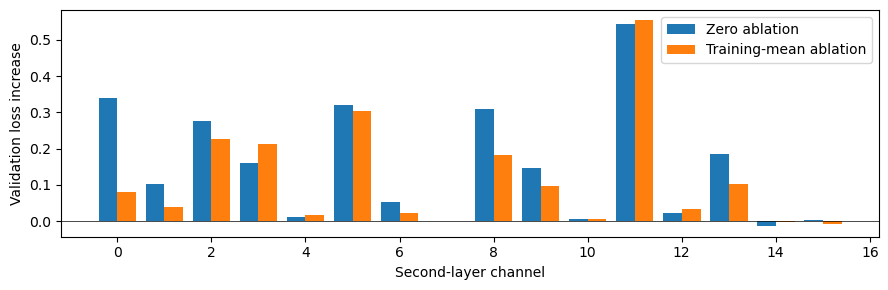

In [74]:
# 3. Causal channel ablations: replace one channel by zero or a training-set mean.
# The mean is one scalar per channel, averaged over training images and spatial positions.
mean_activation = calibration_activations.mean((0, 2, 3), keepdim=True)

@torch.no_grad()
def intervened_logits(images, transform):
    def hook(module, inputs, output):
        return transform(output.clone())
    handle = intervention_layer.register_forward_hook(hook)
    try:
        return trained_cnn(images)
    finally:
        handle.remove()

def ablate_channel(channel, replacement):
    def transform(activation):
        activation[:, channel] = replacement
        return activation
    return transform

no_op = intervened_logits(evaluation_x, lambda activation: activation)
torch.testing.assert_close(no_op, cnn_logits, atol=1e-5, rtol=1e-5)
base_calibration = metrics(calibration_logits, calibration_y)
base_evaluation = metrics(cnn_logits, evaluation_y)
ablation_rows = []
for channel in range(channels):
    cal = intervened_logits(calibration_x, ablate_channel(channel, 0.0))
    zero = intervened_logits(evaluation_x, ablate_channel(channel, 0.0))
    mean = intervened_logits(evaluation_x, ablate_channel(channel, mean_activation[0, channel, 0, 0]))
    ablation_rows.append({
        "channel": channel,
        "selection_loss_increase": metrics(cal, calibration_y)["loss"] - base_calibration["loss"],
        "validation_zero_loss_increase": metrics(zero, evaluation_y)["loss"] - base_evaluation["loss"],
        "validation_mean_loss_increase": metrics(mean, evaluation_y)["loss"] - base_evaluation["loss"],
        "validation_accuracy_drop": base_evaluation["accuracy"] - metrics(zero, evaluation_y)["accuracy"],
    })
ranked = sorted(ablation_rows, key=lambda row: row["selection_loss_increase"], reverse=True)
selected_channel = ranked[0]["channel"]
print("channel | train-selected loss increase | val zero loss increase | val mean loss increase | val accuracy drop")
for row in ranked:
    print(f'{row["channel"]:7d} | {row["selection_loss_increase"]:28.4f} | {row["validation_zero_loss_increase"]:22.4f} | {row["validation_mean_loss_increase"]:22.4f} | {row["validation_accuracy_drop"]:17.4f}')
pyplot.figure(figsize=(9, 3))
pyplot.bar(np.arange(channels) - 0.2, [r["validation_zero_loss_increase"] for r in ablation_rows], width=0.4, label="Zero ablation")
pyplot.bar(np.arange(channels) + 0.2, [r["validation_mean_loss_increase"] for r in ablation_rows], width=0.4, label="Training-mean ablation")
pyplot.axhline(0, color="black", linewidth=0.5)
pyplot.xlabel("Second-layer channel")
pyplot.ylabel("Validation loss increase")
pyplot.legend()
pyplot.tight_layout()
pyplot.show()
summary["ablation"] = ablation_rows
summary["selected_channel"] = selected_channel
# Loss increases measure dependence under this intervention. Zeroing can create
# unusual internal states, and redundant channels can hide useful information.


Clean accuracy: 0.938; corrupted: 0.250
Recovery denominator: 95/128 images are clean-correct with margin drop > 0.1
same_corrupted_donor {'mean_margin_gain_all': 0.0, 'eligible_gap_recovery': 0.0, 'accuracy_all': 0.25}
all_clean_channels {'mean_margin_gain_all': 4.432418346405029, 'eligible_gap_recovery': 1.0, 'accuracy_all': 0.9375}
train_selected_channel {'mean_margin_gain_all': 0.6133009195327759, 'eligible_gap_recovery': 0.16449567675590515, 'accuracy_all': 0.3359375}
mismatched_donor_same_channel {'mean_margin_gain_all': -0.5493925213813782, 'eligible_gap_recovery': -0.030389415100216866, 'accuracy_all': 0.1640625}


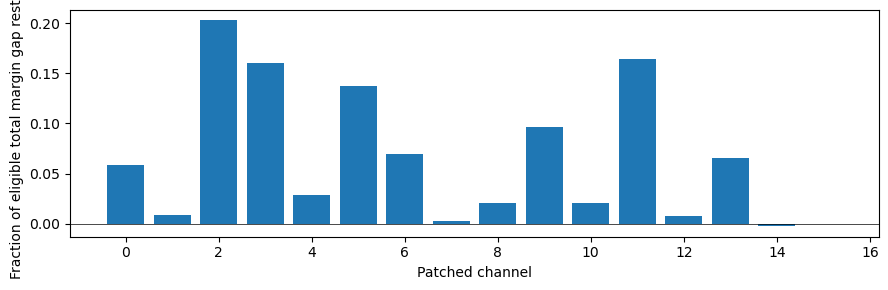

In [75]:
# 4. Activation patching: corrupt pixels, then restore clean internal activations.
# Use a fixed central occlusion and 128 validation images, not a hand-picked success.
clean_x = evaluation_x[:128]
patch_labels = evaluation_y[:128]
corrupt_x = clean_x.clone()
corrupt_x[:, :, 8:20, 8:20] = 0
clean_logits, clean_activations = capture_activations(clean_x)
corrupt_logits, corrupt_activations = capture_activations(corrupt_x)
competing_logits = clean_logits.clone()
competing_logits[torch.arange(len(patch_labels)), patch_labels] = -torch.inf
competitor = competing_logits.argmax(-1)

def fixed_margin(logits):
    rows = torch.arange(len(patch_labels))
    return logits[rows, patch_labels] - logits[rows, competitor]

clean_margin = fixed_margin(clean_logits)
corrupt_margin = fixed_margin(corrupt_logits)
gap = clean_margin - corrupt_margin
eligible = (clean_logits.argmax(-1) == patch_labels) & (gap > 0.1)
print(f"Clean accuracy: {metrics(clean_logits, patch_labels)['accuracy']:.3f}; corrupted: {metrics(corrupt_logits, patch_labels)['accuracy']:.3f}")
print(f"Recovery denominator: {eligible.sum().item()}/{len(eligible)} images are clean-correct with margin drop > 0.1")
assert eligible.any(), "This corruption did not damage any clean-correct examples."

def patch_channel(channel, donor):
    def transform(activation):
        activation[:, channel] = donor[:, channel]
        return activation
    return transform

# Same-corrupted donor is a no-op; restoring the whole clean layer must recover
# the clean output because the remaining network has no bypass connections.
self_patch = intervened_logits(corrupt_x, lambda activation: corrupt_activations.clone())
full_patch = intervened_logits(corrupt_x, lambda activation: clean_activations.clone())
torch.testing.assert_close(self_patch, corrupt_logits, atol=1e-5, rtol=1e-5)
torch.testing.assert_close(full_patch, clean_logits, atol=1e-5, rtol=1e-5)

def recovery(logits):
    gain = fixed_margin(logits) - corrupt_margin
    return {
        "mean_margin_gain_all": gain.mean().item(),
        "eligible_gap_recovery": (gain[eligible].sum() / gap[eligible].sum()).item(),
        "accuracy_all": metrics(logits, patch_labels)["accuracy"],
    }

patch_rows = []
for channel in range(channels):
    patched = intervened_logits(corrupt_x, patch_channel(channel, clean_activations))
    patch_rows.append({"channel": channel, **recovery(patched)})
# A rolled donor preserves plausible activations but mismatches the source image.
selected_patch = intervened_logits(corrupt_x, patch_channel(selected_channel, clean_activations))
mismatched_patch = intervened_logits(corrupt_x, patch_channel(selected_channel, clean_activations.roll(1, 0)))
controls = {
    "same_corrupted_donor": recovery(self_patch),
    "all_clean_channels": recovery(full_patch),
    "train_selected_channel": recovery(selected_patch),
    "mismatched_donor_same_channel": recovery(mismatched_patch),
}
for name, result in controls.items():
    print(name, result)
pyplot.figure(figsize=(9, 3))
pyplot.bar(range(channels), [r["eligible_gap_recovery"] for r in patch_rows])
pyplot.axhline(0, color="black", linewidth=0.5)
pyplot.xlabel("Patched channel")
pyplot.ylabel("Fraction of eligible total margin gap restored")
pyplot.tight_layout()
pyplot.show()
summary["patching"] = {"n": len(patch_labels), "eligible_n": eligible.sum().item(), "channels": patch_rows, "controls": controls}
# Fractions can be negative or exceed one; channel effects need not add up.
# Full-layer recovery is an implementation control, not a discovered circuit.


CNN IG completeness: attribution sum=6.02437, endpoint contrast change=5.96825, numerical residual=0.05612


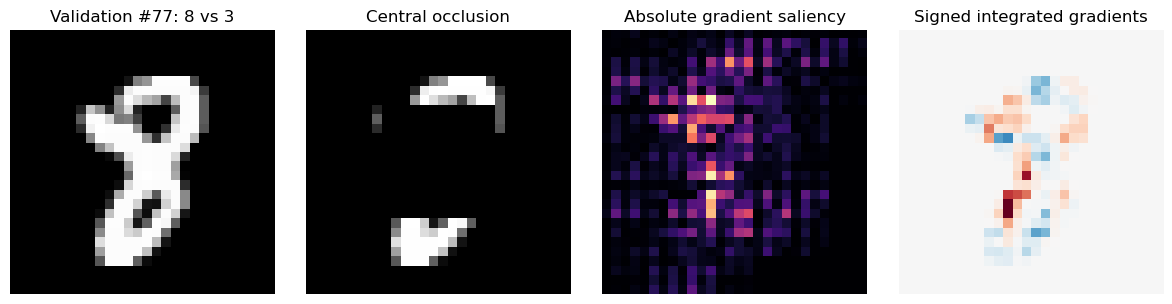

In [76]:
# 5. Gradient saliency and integrated gradients of a fixed class-logit contrast.
# The image below is deliberately the eligible example most damaged by occlusion;
# it illustrates a failure and is not a representative/random evaluation sample.
example = torch.where(eligible, gap, -torch.inf).argmax().item()
clean_image = clean_x[example:example + 1]
label = patch_labels[example].item()
other = competitor[example].item()

def integrated_gradients(net, image, baseline, target, foil, steps=128):
    # Trapezoidal integration along the straight line from baseline to image.
    assert steps > 0
    alphas = torch.linspace(0, 1, steps + 1)
    derivatives = []
    for alpha_chunk in alphas.split(32):
        shape = (-1,) + (1,) * (image.ndim - 1)
        points = baseline + alpha_chunk.reshape(shape) * (image - baseline)
        points = points.detach().requires_grad_(True)
        logits = net(points)
        gradients = torch.autograd.grad((logits[:, target] - logits[:, foil]).sum(), points)[0]
        derivatives.append(gradients.detach())
    gradients = torch.cat(derivatives)
    average_gradient = (gradients[0] / 2 + gradients[1:-1].sum(0) + gradients[-1] / 2) / steps
    return (image - baseline) * average_gradient.unsqueeze(0)

# Independent analytic check: linear-model IG must be input difference times weights.
linear_image = evaluation_x[linear_index:linear_index + 1].flatten(1)
linear_ig = integrated_gradients(trained_linear, linear_image, torch.zeros_like(linear_image), target, foil, steps=8)
analytic = linear_image * (trained_linear.lin.weight[target] - trained_linear.lin.weight[foil])
torch.testing.assert_close(linear_ig, analytic, atol=1e-6, rtol=1e-5)

differentiable_image = clean_image.clone().requires_grad_(True)
logits = trained_cnn(differentiable_image)
saliency = torch.autograd.grad((logits[:, label] - logits[:, other]).sum(), differentiable_image)[0]
baseline = torch.zeros_like(clean_image)
attribution = integrated_gradients(trained_cnn, clean_image, baseline, label, other)
with torch.no_grad():
    endpoints = trained_cnn(torch.cat((clean_image, baseline)))
    contrast_change = (endpoints[0, label] - endpoints[0, other]) - (endpoints[1, label] - endpoints[1, other])
residual = (attribution.sum() - contrast_change).item()
print(f"CNN IG completeness: attribution sum={attribution.sum().item():.5f}, endpoint contrast change={contrast_change.item():.5f}, numerical residual={residual:.5f}")
# CNN IG is numerical; inspect the residual and increase steps if needed.
fig, axes = pyplot.subplots(1, 4, figsize=(12, 3))
axes[0].imshow(clean_image[0, 0], cmap="gray")
axes[0].set_title(f"Validation #{example}: {label} vs {other}")
axes[1].imshow(corrupt_x[example, 0], cmap="gray")
axes[1].set_title("Central occlusion")
axes[2].imshow(saliency[0, 0].abs(), cmap="magma")
axes[2].set_title("Absolute gradient saliency")
bound = attribution.abs().max().item()
axes[3].imshow(attribution[0, 0], cmap="RdBu_r", vmin=-bound, vmax=bound)
axes[3].set_title("Signed integrated gradients")
for ax in axes:
    ax.axis("off")
pyplot.tight_layout()
pyplot.show()
summary["integrated_gradients"] = {"example": example, "steps": 128, "completeness_residual": residual, "contrast_change": contrast_change.item()}
# Attribution depends on the chosen contrast and baseline. A black image is one
# reference, not the unique absence of a digit. Gradients do not identify a circuit.


In [77]:
# Final controls: interventions must leave parameters and ordinary predictions intact.
import json
for name, value in trained_cnn.state_dict().items():
    torch.testing.assert_close(value, original_parameters[name], atol=0, rtol=0)
torch.testing.assert_close(logits_in_batches(trained_cnn, evaluation_x), cnn_logits)
assert not intervention_layer._forward_hooks
assert all(torch.isfinite(torch.tensor(row["eligible_gap_recovery"])) for row in patch_rows)
Path("artifacts").mkdir(exist_ok=True)
(Path("artifacts") / "metrics.json").write_text(json.dumps(summary, indent=2) + "\n")
print("Passed: exact linear decomposition, analytic linear IG, hook/no-op controls,")
print("same-donor patch, full-layer recovery, and unchanged parameters/predictions.")
print("Artifacts: artifacts/metrics.json. Dataset and artifacts are excluded from Git.")


Passed: exact linear decomposition, analytic linear IG, hook/no-op controls,
same-donor patch, full-layer recovery, and unchanged parameters/predictions.
Artifacts: artifacts/metrics.json. Dataset and artifacts are excluded from Git.
